# Mushroom Classification Using Machine Learning

**Goal:** Predict whether a mushroom is labelled edible or poisonous using its physical characteristics.

This supervised learning project compares two classification models:
1. Decision Tree
2. K-Nearest Neighbors (KNN)

**Dataset:** UCI Machine Learning Repository — Mushroom  
https://archive.ics.uci.edu/dataset/73/mushroom



## 1. Import libraries

I used pandas for data handling, scikit-learn for preprocessing and models, and Matplotlib/Seaborn to visualize confusion matrices.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

RANDOM_STATE = 42


## 2. Load the dataset

The UCI dataset contains 8,124 mushroom examples and categorical physical attributes. The target indicates whether each example is edible or poisonous.

In [9]:
mushroom = fetch_ucirepo(id=73)

X = mushroom.data.features.copy()
y = mushroom.data.targets.iloc[:, 0].copy()

print("Feature data shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())
display(y.head())


Feature data shape: (8124, 22)
Target shape: (8124,)


,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,s,n,t,p,f,c,n,k,e,...,s,w,w,p,w,o,p,k,s,u
1,x,s,y,t,a,f,c,b,k,e,...,s,w,w,p,w,o,p,n,n,g
2,b,s,w,t,l,f,c,b,n,e,...,s,w,w,p,w,o,p,n,n,m
3,x,y,w,t,p,f,c,n,n,e,...,s,w,w,p,w,o,p,k,s,u
4,x,s,g,f,n,f,w,b,k,t,...,s,w,w,p,w,o,e,n,a,g


0    p
1    e
2    e
3    p
4    e
Name: poisonous, dtype: object

## 3. Check and prepare the data

First, inspecting missing values and target labels. In this dataset, missing stalk-root values may be encoded as `?`; we convert those markers to proper missing values and impute them with the most frequent category.

All features are categorical, so we use one-hot encoding. The preprocessing is placed inside a pipeline to ensure it is fitted on the training data only.

In [ ]:
X = X.replace("?", np.nan)

print("Missing values per feature (before preprocessing):")
display(X.isna().sum().sort_values(ascending=False).head(10))

print("\nTarget class counts:")
display(y.value_counts(dropna=False))

# Ensure the target is a one-dimensional Series with readable class labels.
y = y.astype(str).str.strip()


Missing values per feature (before preprocessing):


stalk-root         2480
cap-shape             0
cap-color             0
bruises               0
odor                  0
cap-surface           0
gill-attachment       0
gill-spacing          0
gill-color            0
gill-size             0
dtype: int64


Target class counts:


poisonous
e    4208
p    3916
Name: count, dtype: int64

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

categorical_features = X.columns.tolist()

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_preprocessor, categorical_features)
    ]
)

print("Training examples:", X_train.shape[0])
print("Testing examples:", X_test.shape[0])


Training examples: 6499
Testing examples: 1625


## 4. Build the two models

**Decision Tree:** Learns a sequence of feature-based decisions. It is usually easy to interpret.

**K-Nearest Neighbors (KNN):** Predicts a class using the labels of nearby training examples. Here, `k=5` means the five nearest training examples vote on the prediction.

Both models use the same train/test split and preprocessing pipeline for a fair comparison.

In [12]:
decision_tree = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
])

knn = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

decision_tree.fit(X_train, y_train)
knn.fit(X_train, y_train)

print("Both models have been trained.")


Both models have been trained.


## 5. Evaluate and compare

Accuracy is the proportion of test examples classified correctly. A confusion matrix shows correct and incorrect predictions for each class.

For this dataset, the labels are encoded as `e` (edible) and `p` (poisonous) in the original data.

In [13]:
models = {
    "Decision Tree": decision_tree,
    "KNN (k=5)": knn
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
display(results_df.style.format({"Accuracy": "{:.2%}"}))

for name, y_pred in predictions.items():
    print(f"\n{name} classification report:")
    print(classification_report(y_test, y_pred, zero_division=0))


,Model,Accuracy
0,Decision Tree,100.00%
1,KNN (k=5),100.00%



Decision Tree classification report:
              precision    recall  f1-score   support

           e       1.00      1.00      1.00       842
           p       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625


KNN (k=5) classification report:
              precision    recall  f1-score   support

           e       1.00      1.00      1.00       842
           p       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



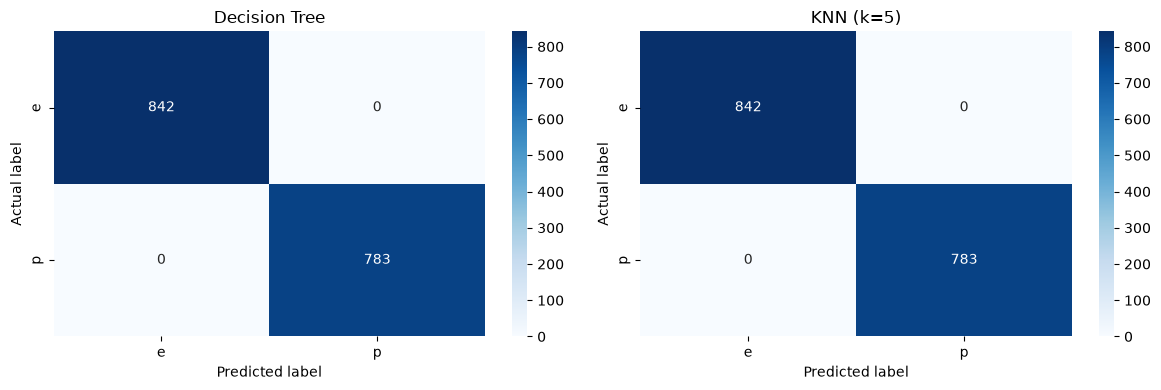

In [ ]:
labels = sorted(y.unique())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=labels, yticklabels=labels, ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.tight_layout()
plt.show()


## 6. Conclusion
- **What I learned:** How to load and inspect a real dataset, handle missing values, encode categorical features, split data into training and testing sets, train two classifiers, and evaluate their predictions.
- **Limitation:** Accuracy on one held-out split does not guarantee performance on new data. Confusion matrices and class-level metrics provide additional context.

